# YOLOv8 Classification Pipeline
Data Prep → Augmentation → Train → Evaluate → Export

**ขั้นตอน:**
1. ติดตั้ง Library
2. ตั้งค่า Configuration
3. เตรียม Dataset Structure
4. Augmentation (Crop, Shear, Saturation, Exposure, Noise) → 100 รูป/class
5. Train YOLOv8-cls (5 class)
6. Evaluate & สรุปผล
7. Export เป็น .onnx


## ติดตั้ง Library

In [1]:
# !pip install ultralytics albumentations opencv-python-headless matplotlib seaborn pandas PyYAML onnxruntime scikit-learn

In [1]:
import os
import cv2
import numpy as np
import shutil
import random
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import pandas as pd
from pathlib import Path
from PIL import Image
import albumentations as A
from ultralytics import YOLO
from sklearn.metrics import classification_report, confusion_matrix
import torch

random.seed(42)
np.random.seed(42)

print(f'PyTorch: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

PyTorch: 2.10.0+cpu
CUDA available: False


## ตั้งค่า Configuration

In [2]:
CLASS_NAMES = [
    'background',
    'crosswalk',
    'stop',
    'stop_ahead',
    'traffic',
    'winding_road'  
]

TARGET_PER_CLASS = 150       # จำนวนรูปที่ต้องการต่อ class
IMG_SIZE        = 224        # Classification ใช้ 224 (ImageNet standard)
EPOCHS          = 5
BATCH_SIZE      = 16
TRAIN_RATIO     = 0.8        # 80% train, 20% val

BASE_DIR    = Path('cls_project')
RAW_DIR     = BASE_DIR / 'raw'        # วางรูปต้นฉบับที่นี่
AUG_DIR     = BASE_DIR / 'augmented' # รูปหลัง augmentation
DATASET_DIR = BASE_DIR / 'dataset'   # dataset สำหรับ YOLO-cls format
RUNS_DIR    = BASE_DIR / 'runs'

NUM_CLASSES = len(CLASS_NAMES)
print(f'   Config โหลดสำเร็จ')
print(f'   Classes ({NUM_CLASSES}): {CLASS_NAMES}')
print(f'   Target per class: {TARGET_PER_CLASS} รูป')
print(f'   Image size: {IMG_SIZE}x{IMG_SIZE}')

   Config โหลดสำเร็จ
   Classes (6): ['background', 'crosswalk', 'stop', 'stop_ahead', 'traffic', 'winding_road']
   Target per class: 150 รูป
   Image size: 224x224


In [ ]:
# # สร้าง folder structure
# for cls in CLASS_NAMES:
#     (RAW_DIR / cls).mkdir(parents=True, exist_ok=True)
#     (AUG_DIR / cls).mkdir(parents=True, exist_ok=True)

# for split in ['train', 'val']:
#     for cls in CLASS_NAMES:
#         (DATASET_DIR / split / cls).mkdir(parents=True, exist_ok=True)

# print('สร้าง Folder Structure สำเร็จ')
# print()
# print('วิธีเตรียมข้อมูล:')
# for cls in CLASS_NAMES:
#     print(f'   cls_project/raw/{cls}/   ← ใส่รูปทั้งหมดของ {cls} ที่นี่')
# print()
# print('ไม่ต้องทำ Bounding Box Label สำหรับ Classification!')

✅ สร้าง Folder Structure สำเร็จ

📌 วิธีเตรียมข้อมูล:
   cls_project/raw/background/   ← ใส่รูปทั้งหมดของ background ที่นี่
   cls_project/raw/crosswalk/   ← ใส่รูปทั้งหมดของ crosswalk ที่นี่
   cls_project/raw/stop/   ← ใส่รูปทั้งหมดของ stop ที่นี่
   cls_project/raw/stop_ahead/   ← ใส่รูปทั้งหมดของ stop_ahead ที่นี่
   cls_project/raw/traffic/   ← ใส่รูปทั้งหมดของ traffic ที่นี่
   cls_project/raw/winding_road/   ← ใส่รูปทั้งหมดของ winding_road ที่นี่

ℹ️  ไม่ต้องทำ Bounding Box Label สำหรับ Classification!


## ตรวจสอบข้อมูลต้นฉบับ

📊 สถานะข้อมูลต้นฉบับ:
----------------------------------------
  ✅ background  :   3 รูป
  ✅ crosswalk   :   1 รูป
  ✅ stop        :   1 รูป
  ✅ stop_ahead  :   1 รูป
  ✅ traffic     :   1 รูป
  ✅ winding_road:   1 รูป
----------------------------------------
  Total: 8 รูป


C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\1745419305.py:31: UserWarning: Glyph 3592 (\N{THAI CHARACTER CHO CHAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\1745419305.py:31: UserWarning: Glyph 3635 (\N{THAI CHARACTER SARA AM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\1745419305.py:31: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\1745419305.py:31: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\1745419305.py:31: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\1745419305.py:31: UserWarning: Glyph 3641 (\N{THAI CHARACTER SARA UU}) m

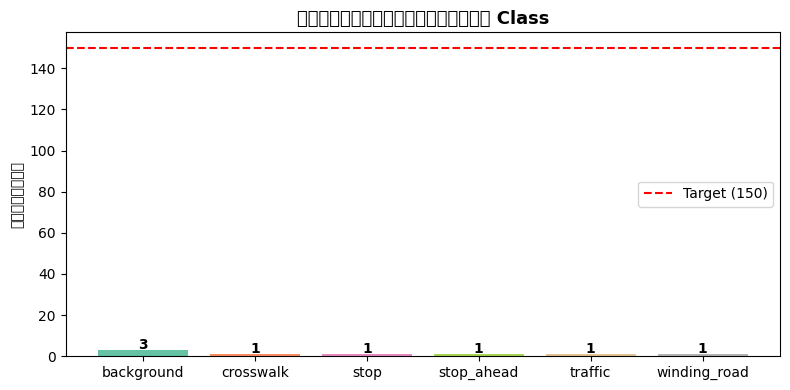

In [4]:
IMG_EXTS = ('*.jpg', '*.jpeg', '*.png', '*.bmp', '*.webp')

def get_images(folder):
    imgs = []
    for ext in IMG_EXTS:
        imgs += list(Path(folder).glob(ext))
    return imgs

print('📊 สถานะข้อมูลต้นฉบับ:')
print('-' * 40)
raw_counts = {}
for cls in CLASS_NAMES:
    imgs = get_images(RAW_DIR / cls)
    raw_counts[cls] = len(imgs)
    status = '✅' if len(imgs) > 0 else '❌'
    print(f'  {status} {cls:12s}: {len(imgs):3d} รูป')
print('-' * 40)
print(f'  Total: {sum(raw_counts.values())} รูป')

# Bar chart
fig, ax = plt.subplots(figsize=(8, 4))
colors_bar = plt.cm.Set2(np.linspace(0, 1, NUM_CLASSES))
bars = ax.bar(CLASS_NAMES, raw_counts.values(), color=colors_bar)
ax.axhline(y=TARGET_PER_CLASS, color='red', linestyle='--', label=f'Target ({TARGET_PER_CLASS})')
ax.set_title('จำนวนรูปต้นฉบับต่อ Class', fontsize=13, fontweight='bold')
ax.set_ylabel('จำนวนรูป')
ax.legend()
for bar, val in zip(bars, raw_counts.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            str(val), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

## Data Augmentation
Crop · Shear · Blur · Exposure · Noise 

Augmentation Pipeline พร้อมแล้ว


C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\2250218619.py:30: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 60.0), p=1.0),


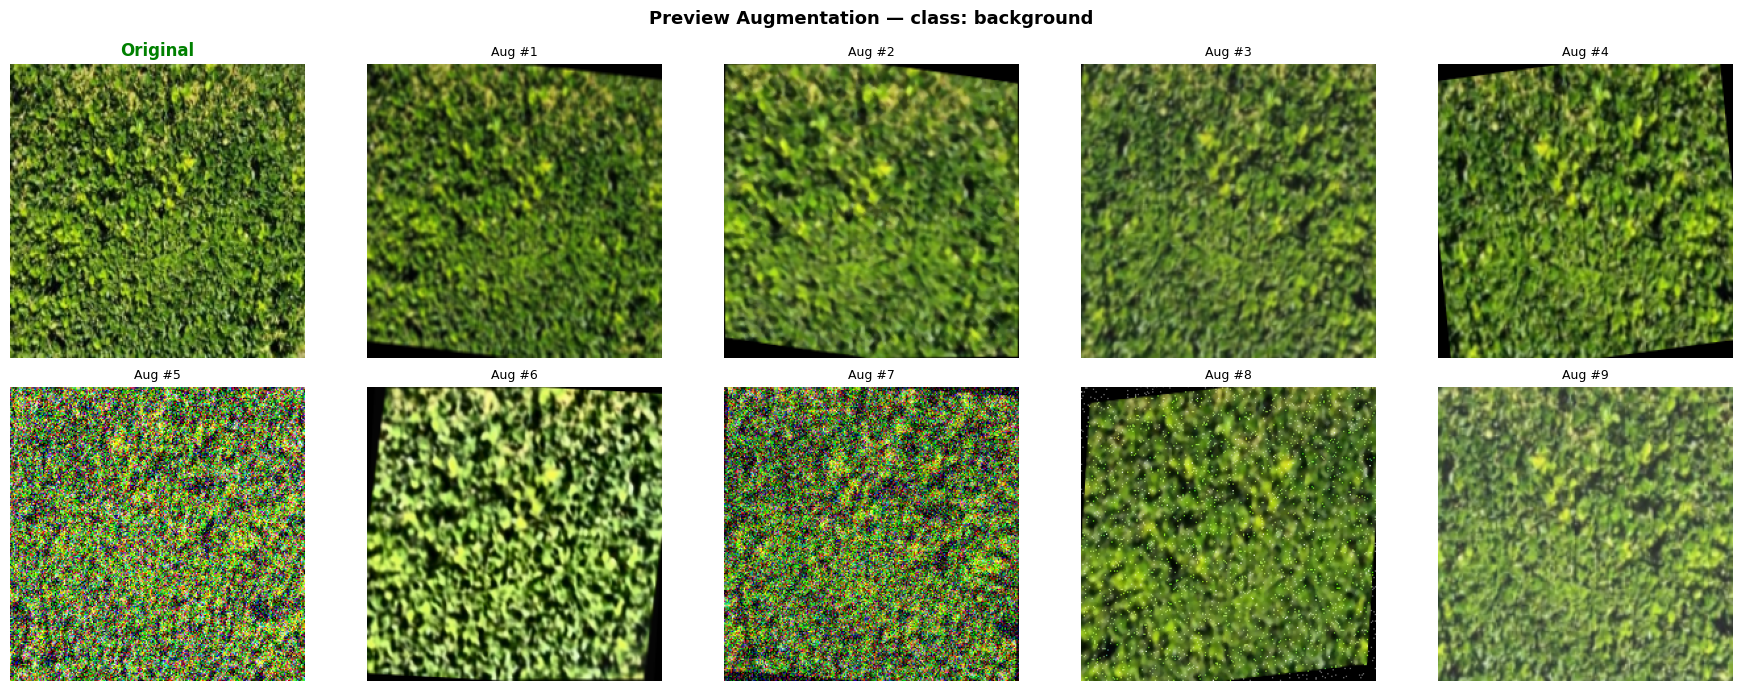

In [5]:
def get_augmentation_pipeline(img_size=224):
    return A.Compose([
        A.Resize(IMG_SIZE,IMG_SIZE),
        # 1. Random Crop
        A.OneOf([
            A.RandomResizedCrop(size=(img_size, img_size), scale=(0.7, 1.0), p=1.0),
            A.CropAndPad(percent=(-0.05, -0.15), p=1.0),
        ], p=0.5),

        # 2. Shear
        A.Affine(shear=(-10, 10), p=0.5),

        # 3. Blur
        A.OneOf([
            A.Blur(blur_limit=3, p=1.0),            # เบลอแบบทั่วไป
            A.GaussianBlur(blur_limit=(3, 5), p=1.0), # เบลอแบบเกาส์เซียน (นุ่มนวลกว่า)
            A.MotionBlur(blur_limit=5, p=1.0),      # เบลอแบบมีความเคลื่อนไหว
            A.MedianBlur(blur_limit=3, p=1.0),      # เบลอแบบลด Noise (ให้ภาพดูละมุน)
        ], p=0.4),

        # 4. Exposure
        A.OneOf([
            A.RandomBrightnessContrast(brightness_limit=0.35, contrast_limit=0.35, p=1.0),
            A.RandomGamma(gamma_limit=(60, 140), p=1.0),
            A.CLAHE(clip_limit=4.0, p=1.0),
        ], p=0.6),

        # 5. Noise
        A.OneOf([
            A.GaussNoise(var_limit=(10.0, 60.0), p=1.0),
            A.ISONoise(color_shift=(0.01, 0.05), intensity=(0.1, 0.5), p=1.0),
            A.MultiplicativeNoise(multiplier=(0.85, 1.15), p=1.0),
        ], p=0.5),

        # Geometric extras
        A.HorizontalFlip(p=0.5),
        A.Rotate(limit=20, p=0.4),
        A.Perspective(scale=(0.05, 0.1), p=0.3),

        # Resize กลับมาที่ขนาด standard
        A.Resize(img_size, img_size),
    ])

print('Augmentation Pipeline พร้อมแล้ว')

# Preview augmentation บนรูปตัวอย่าง
sample_cls = CLASS_NAMES[0]
sample_imgs = get_images(RAW_DIR / sample_cls)

if sample_imgs:
    transform = get_augmentation_pipeline(IMG_SIZE)
    src_img = cv2.imread(str(sample_imgs[0]))
    src_img = cv2.cvtColor(src_img, cv2.COLOR_BGR2RGB)
    src_img_resized = cv2.resize(src_img, (IMG_SIZE, IMG_SIZE))

    fig, axes = plt.subplots(2, 5, figsize=(18, 7))
    axes[0][0].imshow(src_img_resized)
    axes[0][0].set_title('Original', fontweight='bold', color='green')
    axes[0][0].axis('off')

    for idx in range(1, 10):
        row, col = divmod(idx, 5)
        aug = transform(image=src_img)['image']
        axes[row][col].imshow(aug)
        axes[row][col].set_title(f'Aug #{idx}', fontsize=9)
        axes[row][col].axis('off')

    plt.suptitle(f'Preview Augmentation — class: {sample_cls}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print(f'⚠️ ยังไม่มีรูปใน {sample_cls} — รัน create_dummy_data() ก่อน')

In [6]:
def augment_class(cls_name, target_count=100):
    src_dir = RAW_DIR / cls_name
    dst_dir = AUG_DIR / cls_name
    src_imgs = get_images(src_dir)

    if not src_imgs:
        print(f'  ⚠️  {cls_name}: ไม่มีรูปต้นฉบับ')
        return 0

    transform = get_augmentation_pipeline(IMG_SIZE)
    generated = 0

    # copy รูปต้นฉบับก่อน (resize)
    for img_path in src_imgs:
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        out = dst_dir / f'orig_{img_path.stem}.jpg'
        cv2.imwrite(str(out), img_resized)
        generated += 1
        if generated >= target_count:
            return generated

    # Augment จนครบ
    aug_idx = 0
    max_tries = target_count * 10
    while generated < target_count and aug_idx < max_tries:
        img_path = random.choice(src_imgs)
        img = cv2.imread(str(img_path))
        if img is None:
            aug_idx += 1
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        try:
            aug = transform(image=img)['image']
            out = dst_dir / f'aug_{aug_idx:04d}.jpg'
            cv2.imwrite(str(out), cv2.cvtColor(aug, cv2.COLOR_RGB2BGR))
            generated += 1
        except Exception:
            pass
        aug_idx += 1

    return generated


print('🎨 เริ่ม Data Augmentation...')
print('=' * 45)
aug_counts = {}
for cls in CLASS_NAMES:
    count = augment_class(cls, TARGET_PER_CLASS)
    aug_counts[cls] = count
    bar = '█' * count + '░' * (TARGET_PER_CLASS - count)
    print(f'  {cls:12s}: {count:3d}/{TARGET_PER_CLASS}  [{bar}]')

print('=' * 45)
print(f'✅ เสร็จสิ้น! รวม: {sum(aug_counts.values())} รูป')

🎨 เริ่ม Data Augmentation...


C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\2250218619.py:30: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 60.0), p=1.0),


  background  : 150/150  [██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████]
  crosswalk   : 150/150  [██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████]
  stop        : 150/150  [██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████]
  stop_ahead  : 150/150  [██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████]
  traffic     : 150/150  [██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████]
  winding_road: 150/150  [████████████████████████████████████████████████████████████████████████████████████

## สร้าง YOLO Classification Dataset (Train/Val Split)

✅ สร้าง Dataset สำเร็จ!
Class          Train    Val
----------------------------
  background      120     30
  crosswalk       120     30
  stop            120     30
  stop_ahead      120     30
  traffic         120     30
  winding_road    120     30
----------------------------
  Total           720    180


C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\3250863017.py:47: UserWarning: Glyph 3592 (\N{THAI CHARACTER CHO CHAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\3250863017.py:47: UserWarning: Glyph 3635 (\N{THAI CHARACTER SARA AM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\3250863017.py:47: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\3250863017.py:47: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\3250863017.py:47: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\3250863017.py:47: UserWarning: Glyph 3641 (\N{THAI CHARACTER SARA UU}) m

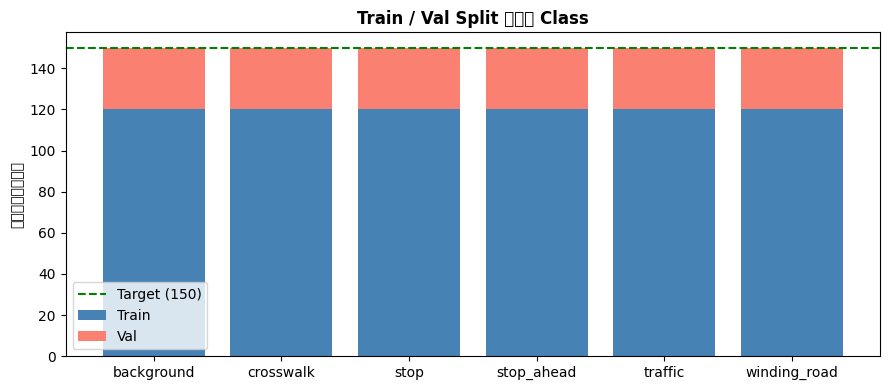

In [7]:
def create_cls_dataset(aug_dir, dataset_dir, class_names, train_ratio=0.8):
    train_counts = {cls: 0 for cls in class_names}
    val_counts   = {cls: 0 for cls in class_names}

    for cls in class_names:
        imgs = get_images(aug_dir / cls)
        random.shuffle(imgs)
        split_idx = int(len(imgs) * train_ratio)
        train_imgs = imgs[:split_idx]
        val_imgs   = imgs[split_idx:]

        for i, p in enumerate(train_imgs):
            dst = dataset_dir / 'train' / cls / f'{cls}_train_{i:04d}{p.suffix}'
            shutil.copy(str(p), str(dst))
        for i, p in enumerate(val_imgs):
            dst = dataset_dir / 'val' / cls / f'{cls}_val_{i:04d}{p.suffix}'
            shutil.copy(str(p), str(dst))

        train_counts[cls] = len(train_imgs)
        val_counts[cls]   = len(val_imgs)

    return train_counts, val_counts


train_counts, val_counts = create_cls_dataset(AUG_DIR, DATASET_DIR, CLASS_NAMES, TRAIN_RATIO)

print('✅ สร้าง Dataset สำเร็จ!')
print(f"{'Class':12s}  {'Train':>6s}  {'Val':>5s}")
print('-' * 28)
for cls in CLASS_NAMES:
    print(f"  {cls:12s}  {train_counts[cls]:>5d}  {val_counts[cls]:>5d}")
print('-' * 28)
print(f"  {'Total':12s}  {sum(train_counts.values()):>5d}  {sum(val_counts.values()):>5d}")

# Stacked bar chart
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(NUM_CLASSES)
b1 = ax.bar(x, train_counts.values(), label='Train', color='steelblue')
b2 = ax.bar(x, val_counts.values(),
            bottom=list(train_counts.values()), label='Val', color='salmon')
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES)
ax.axhline(TARGET_PER_CLASS, color='green', linestyle='--', label=f'Target ({TARGET_PER_CLASS})')
ax.set_title('Train / Val Split ต่อ Class', fontweight='bold')
ax.set_ylabel('จำนวนรูป')
ax.legend()
plt.tight_layout()
plt.show()

## Train YOLOv8 Classification

In [8]:
# ============================================================
# Model Size:
#   yolov8n-cls.pt  Nano   — เร็วที่สุด
#   yolov8s-cls.pt  Small  — แนะนำสำหรับข้อมูลน้อย
#   yolov8m-cls.pt  Medium
#   yolov8l-cls.pt  Large
#   yolov8x-cls.pt  XLarge — แม่นที่สุด
# ============================================================
MODEL_SIZE = 'yolov8s-cls.pt'

model = YOLO(MODEL_SIZE)
print(f'✅ โหลด {MODEL_SIZE} สำเร็จ')
print(f'   Pretrained: ImageNet → Fine-tune เป็น {NUM_CLASSES} classes')

✅ โหลด yolov8s-cls.pt สำเร็จ
   Pretrained: ImageNet → Fine-tune เป็น 6 classes


In [10]:
results = model.train(
    data=str(DATASET_DIR.resolve()),  # path ไป dataset folder (ImageFolder format)
    epochs=50,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    name='yolov8_cls',
    project=str(RUNS_DIR),
    exist_ok=True,
    patience=15,
    save=True,
    device='0' if torch.cuda.is_available() else 'cpu',

    # Hyperparameters
    lr0=0.01,
    lrf=0.01,
    momentum=0.937,
    weight_decay=0.0005,
    dropout=0.2,   # ป้องกัน overfit เมื่อข้อมูลน้อย

    # Built-in augmentation ใน training loop
    fliplr=0.5,
    flipud=0.0,
    hsv_s=0.4,
    hsv_v=0.4,

    verbose=True
)

print('\n✅ Training เสร็จสิ้น!')

Ultralytics 8.4.21  Python-3.11.8 torch-2.10.0+cpu CPU (Intel Core i7-7500U 2.70GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Users\kitti\Desktop\TrafficSound\model_train\cls_project\dataset, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.2, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.4, hsv_v=0.4, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8_cls, nbs=64, nms=False, opset=None, optimize=False, optimizer=aut

## Evaluate & สรุปผล

In [11]:
best_model_path = r"runs\classify\cls_project\runs\yolov8_cls\weights\best.pt"
trained_model = YOLO(str(best_model_path))
print(f'✅ โหลด Best Model: {best_model_path}')

val_results = trained_model.val(
    data=str(DATASET_DIR.resolve()),
    imgsz=IMG_SIZE,
    verbose=True
)

✅ โหลด Best Model: runs\classify\cls_project\runs\yolov8_cls\weights\best.pt
Ultralytics 8.4.21  Python-3.11.8 torch-2.10.0+cpu CPU (Intel Core i7-7500U 2.70GHz)
YOLOv8s-cls summary (fused): 30 layers, 5,082,886 parameters, 0 gradients, 12.5 GFLOPs
train: D:\Users\kitti\Desktop\TrafficSound\model_train\cls_project\dataset\train... found 720 images in 6 classes  
val: D:\Users\kitti\Desktop\TrafficSound\model_train\cls_project\dataset\val... found 180 images in 6 classes  
test: None...
val: Fast image access  (ping: 0.20.1 ms, read: 16.818.0 MB/s, size: 37.5 KB)
val: Scanning D:\Users\kitti\Desktop\TrafficSound\model_train\cls_project\dataset\val... 180 images, 0 corrupt: 100% ━━━━━━━━━━━━ 180/180  0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 12/12 1.1it/s 10.7s1.0s
                   all          1          1
Speed: 0.0ms preprocess, 46.3ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to D:\Users\kitti\Desktop\TrafficSound\model_train\runs\c

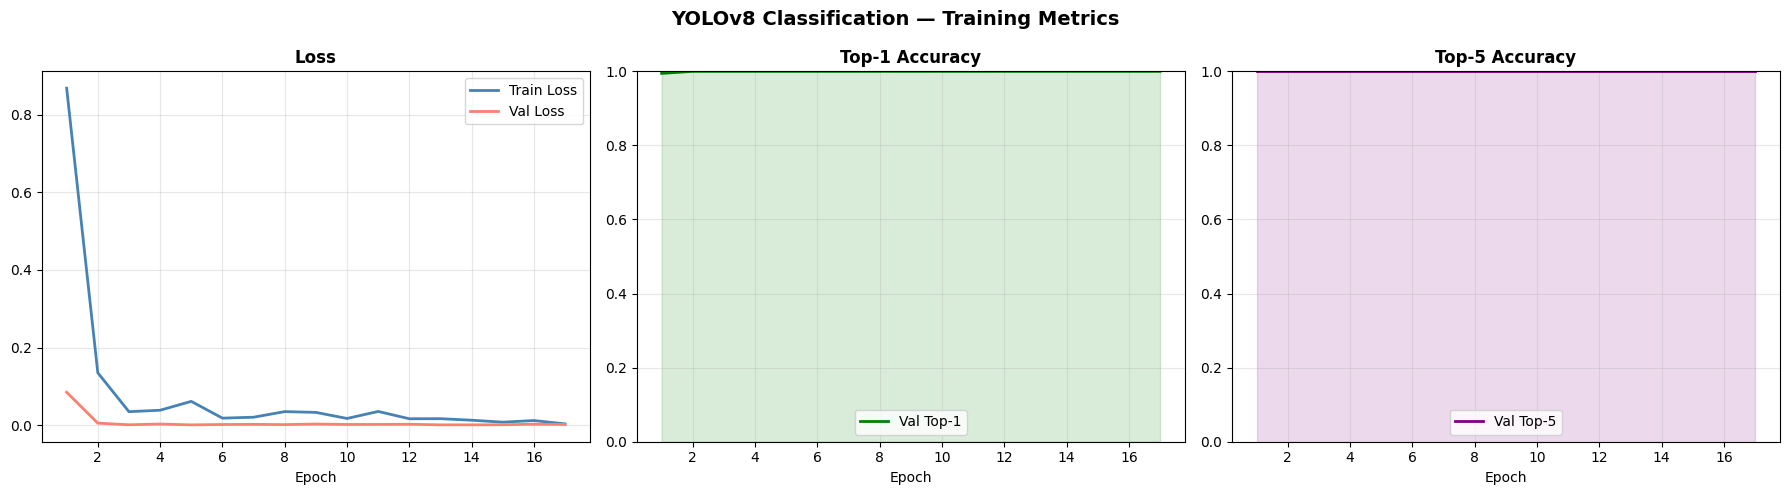

✅ บันทึกกราฟ → training_metrics.png


In [13]:
# ============================================================
# 📈 Training Curves
# ============================================================
results_csv = Path(r"runs\classify\cls_project\runs\yolov8_cls\results.csv")

if results_csv.exists():
    df = pd.read_csv(results_csv)
    df.columns = df.columns.str.strip()

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('YOLOv8 Classification — Training Metrics', fontsize=14, fontweight='bold')
    epochs_x = range(1, len(df) + 1)

    # Loss
    for col, label, color in [('train/loss', 'Train Loss', 'steelblue'),
                               ('val/loss',   'Val Loss',   'salmon')]:
        if col in df.columns:
            axes[0].plot(epochs_x, df[col], label=label, color=color, linewidth=2)
    axes[0].set_title('Loss', fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Top-1 Accuracy
    for col, label, color in [('metrics/accuracy_top1', 'Val Top-1', 'green')]:
        if col in df.columns:
            axes[1].plot(epochs_x, df[col], label=label, color=color, linewidth=2)
            axes[1].fill_between(epochs_x, df[col], alpha=0.15, color=color)
    axes[1].set_title('Top-1 Accuracy', fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylim(0, 1)
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    # Top-5 Accuracy
    for col, label, color in [('metrics/accuracy_top5', 'Val Top-5', 'purple')]:
        if col in df.columns:
            axes[2].plot(epochs_x, df[col], label=label, color=color, linewidth=2)
            axes[2].fill_between(epochs_x, df[col], alpha=0.15, color=color)
    axes[2].set_title('Top-5 Accuracy', fontweight='bold')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylim(0, 1)
    axes[2].legend()
    axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(str(BASE_DIR / 'training_metrics.png'), dpi=150, bbox_inches='tight')
    plt.show()
    print('✅ บันทึกกราฟ → training_metrics.png')
else:
    print('⚠️ ไม่พบ results.csv')

In [14]:
# ============================================================
# 🔍 Inference บน Validation Set + เก็บ Predictions
# ============================================================
y_true, y_pred, y_conf = [], [], []
val_sample_imgs, val_sample_preds, val_sample_trues, val_sample_confs = [], [], [], []

for cls_id, cls in enumerate(CLASS_NAMES):
    val_imgs = list((DATASET_DIR / 'val' / cls).glob('*.jpg'))[:20]  # สูงสุด 20/class
    if not val_imgs:
        continue

    preds = trained_model.predict(source=val_imgs, imgsz=IMG_SIZE, verbose=False)
    for img_path, pred in zip(val_imgs, preds):
        pred_cls_id = int(pred.probs.top1)
        conf = float(pred.probs.top1conf)
        y_true.append(cls_id)
        y_pred.append(pred_cls_id)
        y_conf.append(conf)

        # เก็บตัวอย่างสำหรับแสดงผล
        if len(val_sample_imgs) < 10:
            val_sample_imgs.append(str(img_path))
            val_sample_preds.append(pred_cls_id)
            val_sample_trues.append(cls_id)
            val_sample_confs.append(conf)

print(f'✅ Inference เสร็จ — {len(y_true)} รูป')

✅ Inference เสร็จ — 120 รูป


In [15]:
# ============================================================
# 📊 Classification Report
# ============================================================
print('=' * 60)
print('📋 สรุปผล Classification Report')
print('=' * 60)
report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4)
print(report)

# Overall Accuracy
accuracy = np.mean(np.array(y_true) == np.array(y_pred))
avg_conf = np.mean(y_conf)

if accuracy >= 0.9:
    quality = '🏆 ดีเยี่ยม (Excellent)'
elif accuracy >= 0.75:
    quality = '✅ ดี (Good)'
elif accuracy >= 0.6:
    quality = '⚠️ พอใช้ (Fair)'
else:
    quality = '❌ ต้องปรับปรุง (Poor)'

print(f'Overall Accuracy   : {accuracy:.4f} ({accuracy*100:.2f}%)')
print(f'Avg Confidence     : {avg_conf:.4f}')
print(f'ประเมินผล          : {quality}')

if accuracy < 0.75:
    print()
    print('💡 คำแนะนำ:')
    print('  • เพิ่มข้อมูล training ต่อ class')
    print('  • ตรวจสอบคุณภาพรูป ให้ชัดเจน')
    print('  • เพิ่ม epochs หรือปรับ lr')
    print('  • ลอง model size ใหญ่ขึ้น')

📋 สรุปผล Classification Report
              precision    recall  f1-score   support

  background     1.0000    1.0000    1.0000        20
   crosswalk     1.0000    1.0000    1.0000        20
        stop     1.0000    1.0000    1.0000        20
  stop_ahead     1.0000    1.0000    1.0000        20
     traffic     1.0000    1.0000    1.0000        20
winding_road     1.0000    1.0000    1.0000        20

    accuracy                         1.0000       120
   macro avg     1.0000    1.0000    1.0000       120
weighted avg     1.0000    1.0000    1.0000       120

Overall Accuracy   : 1.0000 (100.00%)
Avg Confidence     : 0.9981
ประเมินผล          : 🏆 ดีเยี่ยม (Excellent)


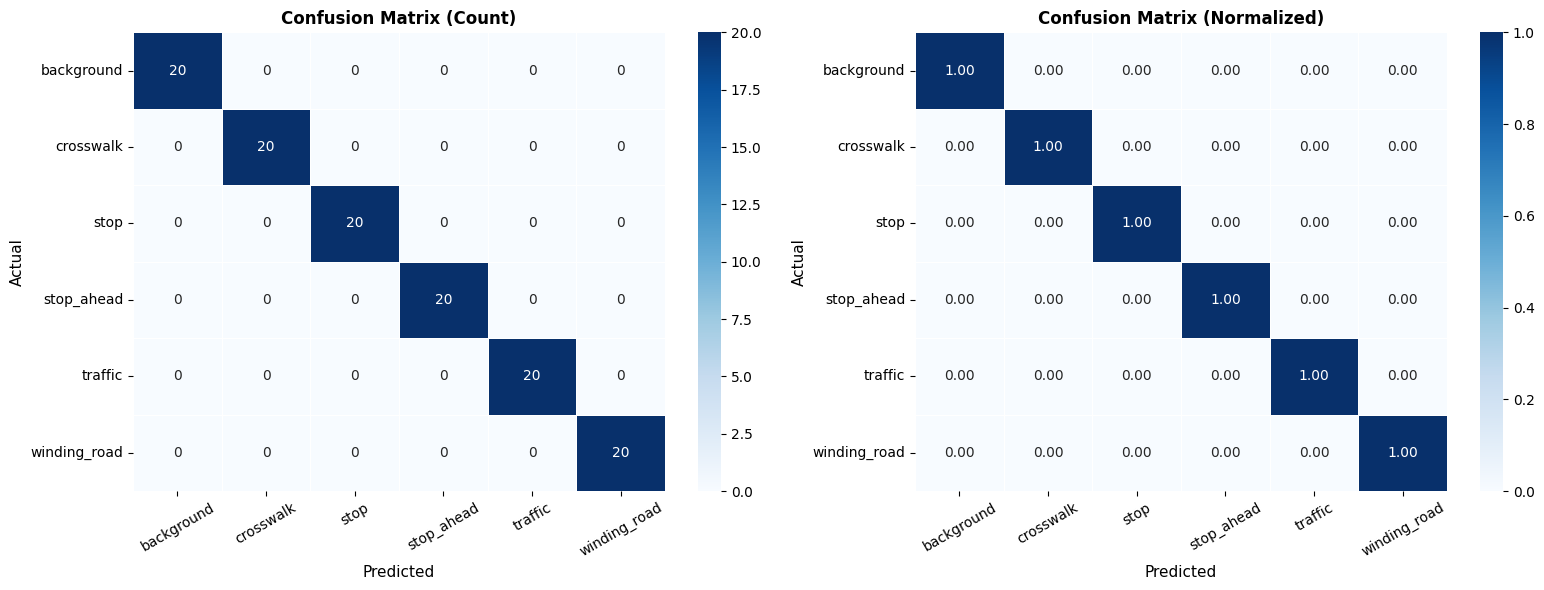

✅ บันทึก → confusion_matrix.png


In [16]:
# ============================================================
# 🗺️ Confusion Matrix
# ============================================================
cm_data = confusion_matrix(y_true, y_pred)
cm_norm = cm_data.astype(float) / cm_data.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, data, title, fmt in [
    (axes[0], cm_data, 'Confusion Matrix (Count)',       'd'),
    (axes[1], cm_norm, 'Confusion Matrix (Normalized)',  '.2f')
]:
    sns.heatmap(
        data, annot=True, fmt=fmt, cmap='Blues',
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
        ax=ax, linewidths=0.5
    )
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted', fontsize=11)
    ax.set_ylabel('Actual',    fontsize=11)
    ax.tick_params(axis='x', rotation=30)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig(str(BASE_DIR / 'confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()
print('✅ บันทึก → confusion_matrix.png')

C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\1951821309.py:32: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\1951821309.py:32: UserWarning: Glyph 3612 (\N{THAI CHARACTER PHO PHUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\1951821309.py:32: UserWarning: Glyph 3621 (\N{THAI CHARACTER LO LING}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\1951821309.py:32: UserWarning: Glyph 3585 (\N{THAI CHARACTER KO KAI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\1951821309.py:32: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kitti\AppData\Local\Temp\ipykernel_17388\1951821309.py:32: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA})

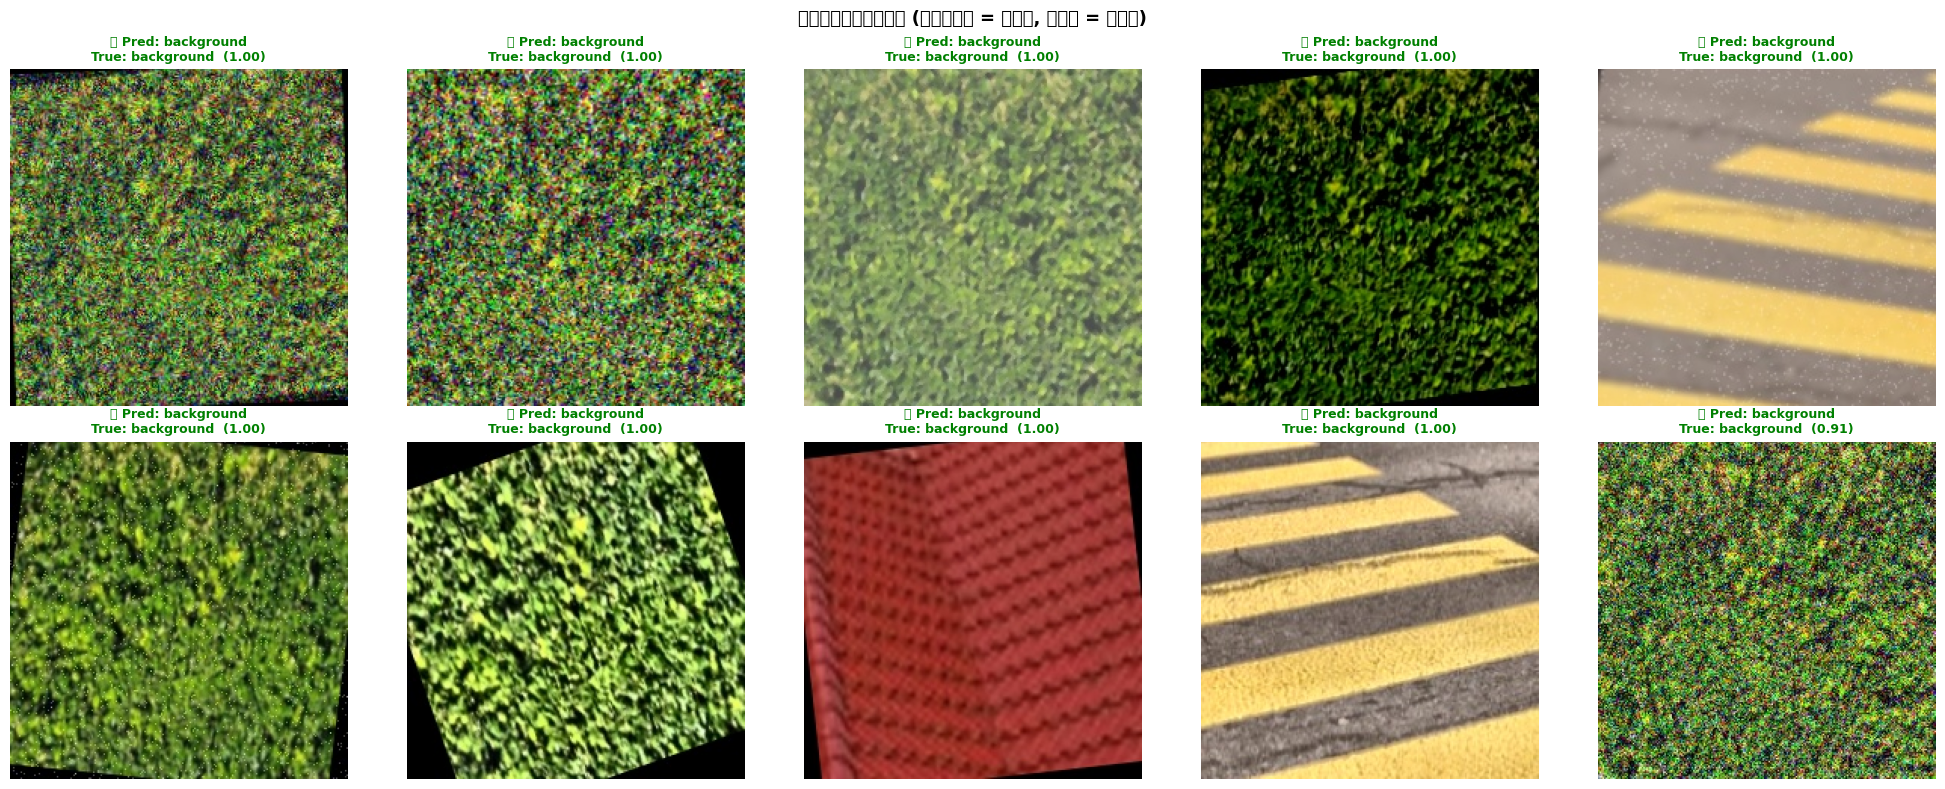

✅ บันทึก → predictions.png


In [17]:
# ============================================================
# 🖼️ ตัวอย่าง Prediction (ถูก = เขียว, ผิด = แดง)
# ============================================================
n = len(val_sample_imgs)
cols = 5
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 4*rows))
axes = np.array(axes).flatten()

for i in range(n):
    img = cv2.imread(val_sample_imgs[i])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    correct = val_sample_preds[i] == val_sample_trues[i]
    pred_name  = CLASS_NAMES[val_sample_preds[i]] if val_sample_preds[i] < len(CLASS_NAMES) else '?'
    true_name  = CLASS_NAMES[val_sample_trues[i]] if val_sample_trues[i] < len(CLASS_NAMES) else '?'
    color = 'green' if correct else 'red'
    icon  = '✅' if correct else '❌'
    axes[i].imshow(img)
    axes[i].set_title(
        f"{icon} Pred: {pred_name}\nTrue: {true_name}  ({val_sample_confs[i]:.2f})",
        fontsize=9, color=color, fontweight='bold'
    )
    for spine in axes[i].spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(3)
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

plt.suptitle('ผลการทำนาย (เขียว = ถูก, แดง = ผิด)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(str(BASE_DIR / 'predictions.png'), dpi=150, bbox_inches='tight')
plt.show()
print('✅ บันทึก → predictions.png')

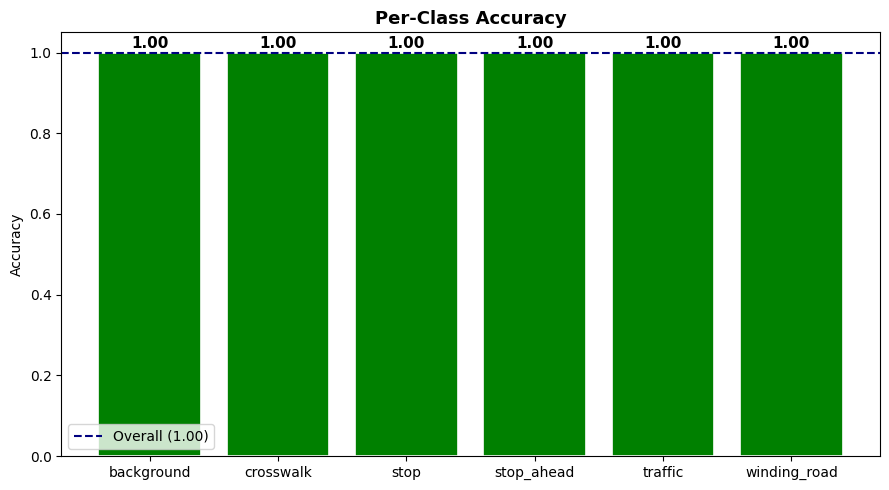

✅ บันทึก → per_class_accuracy.png


In [18]:
# ============================================================
# 📊 Per-Class Accuracy Bar Chart
# ============================================================
y_true_arr = np.array(y_true)
y_pred_arr = np.array(y_pred)
per_class_acc = []

for cls_id, cls in enumerate(CLASS_NAMES):
    mask = y_true_arr == cls_id
    if mask.sum() > 0:
        acc = (y_pred_arr[mask] == cls_id).mean()
    else:
        acc = 0.0
    per_class_acc.append(acc)

fig, ax = plt.subplots(figsize=(9, 5))
bar_colors = ['green' if a >= 0.8 else 'orange' if a >= 0.6 else 'red' for a in per_class_acc]
bars = ax.bar(CLASS_NAMES, per_class_acc, color=bar_colors, edgecolor='white', linewidth=1.2)
ax.axhline(accuracy, color='navy', linestyle='--', linewidth=1.5, label=f'Overall ({accuracy:.2f})')
ax.set_ylim(0, 1.05)
ax.set_title('Per-Class Accuracy', fontsize=13, fontweight='bold')
ax.set_ylabel('Accuracy')
ax.legend()
for bar, val in zip(bars, per_class_acc):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.2f}', ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(str(BASE_DIR / 'per_class_accuracy.png'), dpi=150, bbox_inches='tight')
plt.show()
print('✅ บันทึก → per_class_accuracy.png')

## Export เป็น .onnx

In [19]:
print('📤 กำลัง Export เป็น ONNX...')

onnx_path = trained_model.export(
    format='onnx',
    imgsz=IMG_SIZE,
    simplify=True,
    opset=11,
    dynamic=False,
)

output_onnx = BASE_DIR / 'yolov8_cls_5class.onnx'
shutil.copy(str(onnx_path), str(output_onnx))

size_mb = os.path.getsize(str(output_onnx)) / (1024 * 1024)
print(f'✅ Export สำเร็จ!')
print(f'   Path: {output_onnx}')
print(f'   Size: {size_mb:.2f} MB')

📤 กำลัง Export เป็น ONNX...
Ultralytics 8.4.21  Python-3.11.8 torch-2.10.0+cpu CPU (Intel Core i7-7500U 2.70GHz)

PyTorch: starting from 'runs\classify\cls_project\runs\yolov8_cls\weights\best.pt' with input shape (1, 3, 224, 224) BCHW and output shape(s) (1, 6) (9.8 MB)

ONNX: starting export with onnx 1.20.1 opset 11...
ONNX: slimming with onnxslim 0.1.87...
ONNX: export success  8.5s, saved as 'runs\classify\cls_project\runs\yolov8_cls\weights\best.onnx' (19.4 MB)

Export complete (8.8s)
Results saved to D:\Users\kitti\Desktop\TrafficSound\model_train\runs\classify\cls_project\runs\yolov8_cls\weights
Predict:         yolo predict task=classify model=runs\classify\cls_project\runs\yolov8_cls\weights\best.onnx imgsz=224 
Validate:        yolo val task=classify model=runs\classify\cls_project\runs\yolov8_cls\weights\best.onnx imgsz=224 data=D:\Users\kitti\Desktop\TrafficSound\model_train\cls_project\dataset  
Visualize:       https://netron.app
✅ Export สำเร็จ!
   Path: cls_project\yol

In [20]:
with open('cls_project/label.txt', 'w') as f:
    for name in CLASS_NAMES:
        f.write(name + '\n')

🔍 ONNX Model Info:
   Input  name : images
   Input  shape: [1, 3, 224, 224]
   Output name : output0
   Output shape: [1, 6]  ← [batch, 6] softmax probabilities

✅ ONNX Inference ทำงานได้!
   Output shape: (1, 6)
   Predicted class: background (conf=0.9996)


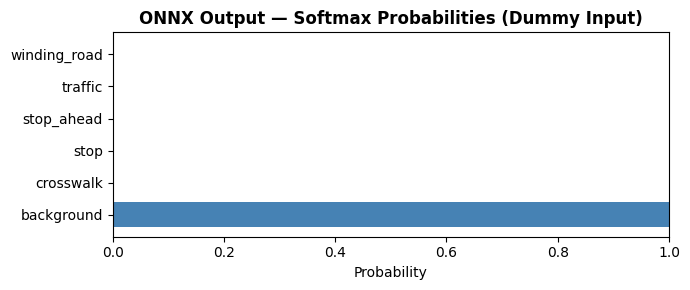

In [21]:
# ============================================================
# ✅ ทดสอบ ONNX Model
# ============================================================
import onnxruntime as ort

sess = ort.InferenceSession(str(output_onnx))

print('🔍 ONNX Model Info:')
inp = sess.get_inputs()[0]
out = sess.get_outputs()[0]
print(f'   Input  name : {inp.name}')
print(f'   Input  shape: {inp.shape}')
print(f'   Output name : {out.name}')
print(f'   Output shape: {out.shape}  ← [batch, {NUM_CLASSES}] softmax probabilities')

# Test inference
dummy = np.random.randn(1, 3, IMG_SIZE, IMG_SIZE).astype(np.float32)
output = sess.run(None, {inp.name: dummy})
probs = output[0][0]  # softmax

print(f'\n✅ ONNX Inference ทำงานได้!')
print(f'   Output shape: {output[0].shape}')
print(f'   Predicted class: {CLASS_NAMES[np.argmax(probs)]} (conf={probs.max():.4f})')

# Softmax visualization
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(CLASS_NAMES, probs, color='steelblue')
ax.set_xlim(0, 1)
ax.set_title('ONNX Output — Softmax Probabilities (Dummy Input)', fontweight='bold')
ax.set_xlabel('Probability')
plt.tight_layout()
plt.show()

In [22]:
# ============================================================
# 🎉 สรุปสุดท้าย
# ============================================================
print('=' * 60)
print('🎉 Pipeline เสร็จสมบูรณ์!')
print('=' * 60)
print(f'  Accuracy  : {accuracy*100:.2f}%')
print(f'  Avg Conf  : {avg_conf:.4f}')
print()
print('📁 ไฟล์ที่ได้:')
print(f'  📈 training_metrics.png')
print(f'  🗺️  confusion_matrix.png')
print(f'  🖼️  predictions.png')
print(f'  📊 per_class_accuracy.png')
print(f'  🧠 best.pt  (PyTorch)')
print(f'  🚀 yolov8_cls_5class.onnx')
print()
print('📌 ONNX Input  : float32 [1, 3, 224, 224]  (normalized 0-1)')
print(f'📌 ONNX Output : float32 [1, {NUM_CLASSES}]  (softmax probabilities)')
print(f'📌 Classes     : {CLASS_NAMES}')
print('=' * 60)

🎉 Pipeline เสร็จสมบูรณ์!
  Accuracy  : 100.00%
  Avg Conf  : 0.9981

📁 ไฟล์ที่ได้:
  📈 training_metrics.png
  🗺️  confusion_matrix.png
  🖼️  predictions.png
  📊 per_class_accuracy.png
  🧠 best.pt  (PyTorch)
  🚀 yolov8_cls_5class.onnx

📌 ONNX Input  : float32 [1, 3, 224, 224]  (normalized 0-1)
📌 ONNX Output : float32 [1, 6]  (softmax probabilities)
📌 Classes     : ['background', 'crosswalk', 'stop', 'stop_ahead', 'traffic', 'winding_road']
